In [41]:
import numpy as np
import sympy as sym
from sympy import symbols, Eq, pprint, init_printing
import scipy.integrate
import matplotlib.pyplot as plt
import json
from IPython.display import display
from publish_format import *
sym.init_printing()

#### Cohesive network [PDS5, Wapl, Sororin, unloading]

In [2]:
## Rates for cohesive network 
rates_coh = sym.symbols("K_RP_RPW, K_RPW_RP, K_RP_RPS, K_RPS_RP, K_RP_R, K_R_RP, K_RPW_R_free")
K_RP_RPW, K_RPW_RP, K_RP_RPS, K_RPS_RP, K_RP_R, K_R_RP, K_RPW_R_free = rates_coh

parameters_coh = sym.symbols("tau_S, F_S, N_S, tau_W, F_W, N_W, tau_P, F_P, N_P, tau_R, F_R_sister, N_R")
tau_S, F_S, N_S, tau_W, F_W, N_W, tau_P, F_P, N_P, tau_R, F_R_sister, N_R = parameters_coh 

## Equations for cohesive network
rhs_coh = [ K_RPW_R_free * N_W * F_W - F_R_sister*N_R/tau_R,    # RAD21 unbinding 
        F_W/(tau_W * (1-F_W)) - K_RP_RPW*(F_P*N_P - F_S*N_S - F_W*N_W), # Wapl binding 
        K_RPW_RP + K_RPW_R_free - 1/tau_W,              # Wapl unbinding  
        F_S/(tau_S * (1-F_S)) - K_RP_RPS * (F_P*N_P - F_S*N_S - F_W*N_W), # Sororin binding
        K_RPS_RP - 1/tau_S,          # Sororin unbinding
        F_P/(tau_P * (1-F_P)) - K_R_RP * (F_R_sister*N_R - F_P * N_P), # PDS5 binding
        K_RPW_R_free * F_W *N_W + K_RP_R*(F_P*N_P - F_S*N_S - F_W*N_W) - F_P*N_P/tau_P,   # PDS5 unbinding  
]

## solutions cohesive network
sol_rates_coh = sym.solve(rhs_coh, rates_coh)

for i, eq in enumerate(rhs_coh, 1):
    pprint(Eq(symbols(f"eq_{i}"), eq))

        F_R_sister⋅N_R                       
eq₁ = - ────────────── + F_W⋅K_RPW_R_free⋅N_W
             τ_R                             
           F_W                                              
eq₂ = ───────────── - K_RP_RPW⋅(F_P⋅N_P - F_S⋅N_S - F_W⋅N_W)
      τ_W⋅(1 - F_W)                                         
                                 1 
eq₃ = K_RPW_RP + K_RPW_R_free - ───
                                τ_W
           F_S                                              
eq₄ = ───────────── - K_RP_RPS⋅(F_P⋅N_P - F_S⋅N_S - F_W⋅N_W)
      τ_S⋅(1 - F_S)                                         
                  1 
eq₅ = K_RPS_RP - ───
                 τ_S
           F_P                                          
eq₆ = ───────────── - K_R_RP⋅(-F_P⋅N_P + F_R_sister⋅N_R)
      τ_P⋅(1 - F_P)                                     
        F_P⋅N_P                                                              
eq₇ = - ─────── + F_W⋅K_RPW_R_free⋅N_W + K_RP_R⋅(F_P⋅N_P - F_S⋅N_S - F_W⋅N_W

#### Extrusive network [Nipbl, PDS5, Wapl, unloading]

In [3]:
## Rates for extrusive network 
rates_ext = sym.symbols("Kext_Rfree_RN, Kext_RN_R, Kext_R_RN, Kext_R_RP, Kext_RP_R, Kext_RP_RPW, Kext_RPW_RP, Kext_RPW_Rfree")
Kext_Rfree_RN, Kext_RN_R, Kext_R_RN, Kext_R_RP, Kext_RP_R, Kext_RP_RPW, Kext_RPW_RP, Kext_RPW_Rfree = rates_ext

parameters_ext = sym.symbols("tau_N_ext, F_N_ext, N_N_ext, tau_W_ext, F_W_ext, N_W_ext, tau_P_ext, F_P_ext, N_P_ext, tau_R_ext, F_R_ext, N_R_ext")
tau_N_ext, F_N_ext, N_N_ext, tau_W_ext, F_W_ext, N_W_ext, tau_P_ext, F_P_ext, N_P_ext, tau_R_ext, F_R_ext, N_R_ext = parameters_ext

## Equations for extrusive network 
rhs_ext = [ Kext_RN_R - 1 / tau_N_ext,  # NIPBL unbinding kinetics
        Kext_Rfree_RN * N_R_ext *(1-F_R_ext) + Kext_R_RN * (N_R_ext*F_R_ext - N_N_ext*F_N_ext - N_P_ext*F_P_ext) -  F_N_ext / tau_N_ext/ (1-F_N_ext), # NIPBL binding equilibrium
        Kext_RP_R * (N_P_ext * F_P_ext - N_W_ext * F_W_ext) + Kext_RPW_Rfree * N_W_ext * F_W_ext  - N_P_ext * F_P_ext/tau_P_ext, # PDS5 unbinding kinetics
        Kext_R_RP * (N_R_ext * F_R_ext - N_N_ext * F_N_ext - N_P_ext * F_P_ext)  - F_P_ext / tau_P_ext /(1-F_P_ext), # PDS5 binding equilibrium,
        Kext_RPW_RP + Kext_RPW_Rfree - 1 / tau_W_ext, # WAPL unbinding kinetics
        Kext_RP_RPW * (N_P_ext * F_P_ext - N_W_ext* F_W_ext)  - F_W_ext / tau_W_ext / (1-F_W_ext), # WAPL binding equilibrium
        Kext_RPW_Rfree * N_W_ext * F_W_ext - F_R_ext * N_R_ext / tau_R_ext,  # RAD21 unbinding kinetics
        Kext_Rfree_RN * N_N_ext * (1-F_N_ext) - F_R_ext / tau_R_ext / (1-F_R_ext) # RAD21 binding equilibrium, 
]

## solutions extrusive network
sol_rates_ext = sym.solve(rhs_ext, rates_ext)
for i, eq in enumerate(rhs_ext, 1):
    pprint(Eq(symbols(f"eq_{i}"), eq))

                     1   
eq₁ = Kext_RN_R - ───────
                  τ_N_ext
               F_N_ext                                                        
eq₂ = - ───────────────────── + Kext_R_RN⋅(-F_N_ext⋅N_N_ext - F_P_ext⋅N_P_ext 
        τ_N_ext⋅(1 - F_N_ext)                                                 

                                                        
+ F_R_ext⋅N_R_ext) + Kext_Rfree_RN⋅N_R_ext⋅(1 - F_R_ext)
                                                        
        F_P_ext⋅N_P_ext                                                       
eq₃ = - ─────────────── + F_W_ext⋅Kext_RPW_Rfree⋅N_W_ext + Kext_RP_R⋅(F_P_ext⋅
            τ_P_ext                                                           

                          
N_P_ext - F_W_ext⋅N_W_ext)
                          
               F_P_ext                                                        
eq₄ = - ───────────────────── + Kext_R_RP⋅(-F_N_ext⋅N_N_ext - F_P_ext⋅N_P_ext 
        τ_P_ext⋅(1 - F_P_ext)       

In [4]:
with open("parameters.json", "r") as f:
    PARAMS = json.load(f)

In [5]:
def get_parameter_dict_coh(x, y):
    p = PARAMS["cohesive"]
    parameter_values_coh = [
        p["tau_S"],
        p["F_S"],
        p["N_S"],
        p["tau_W"],
        x / (p["x_offset_W"] + x),                        # modified F_W for sister
        p["N_W_base"] * (p["x_offset_W"] + x),            # modified N_W for sister
        p["tau_P"],
        y / (p["y_offset_P"] + y),                        # modified F_P for sister
        p["N_P_base"] * (p["y_offset_P"] + y),            # modified N_P for sister
        p["tau_R_sister"],
        p["F_R_sister"],
        p["N_R_modify"],                                 
    ]
    return dict(zip(parameters_coh, parameter_values_coh))


def get_parameter_dict_ext(x, y):
    p = PARAMS["extrusive"]
    parameter_values_ext = [
        p["tau_N"],
        p["F_N"],
        p["N_N"],
        p["tau_W"],
        (p["F_W_base"] - x) / (1 - x),                   # modified F_W for extrusive
        p["N_W_base"] * (1 - x),                          # modified N_W for extrusive
        p["tau_P"],
        (p["F_P_base"] - y) / (1 - y),                   # modified F_P for extrusive
        p["N_P_base"] * (1 - y),                          # modified N_P for extrusive
        p["tau_R_extrusive"],
        p["F_R_sister"],
        p["N_R_modify"],
    ]
    return dict(zip(parameters_ext, parameter_values_ext))


In [6]:
# Define a function to check if the solutions are positive for cohesive network
def check_positive_solutions_coh(x, y):
    parameter_dict = get_parameter_dict_coh(x, y)
    # Evaluate each rate and check if it's positive and non-zero
    rates = []
    for s in sol_rates_coh.items():
        rate = s[1].evalf(subs=parameter_dict)
        rates.append(rate)
        if rate.is_positive is not True: 
            return False, rates
    return True, rates  #

# Define a function to check if the solutions are positive for extrusive network
def check_positive_solutions_ext(x, y):
    parameter_dict_ext = get_parameter_dict_ext(x, y)
    # Evaluate each rate and check if it's positive and non-zero
    rates = []
    for s in sol_rates_ext.items():
        rate = s[1].evalf(subs = parameter_dict_ext)
        rates.append(rate)
        if rate.is_positive is not True: 
            return False, rates
    return True, rates 

In [31]:
# Create a grid of x and y values
## x is the fraction of Wapl bounded at sisterCs which is betwwen 0 and 0.35
## y is the fraction of PDS5 bounded at sisterCs which is between 0 and 0.42
x_values = np.linspace(1e-11, 0.345, 500)  
y_values = np.linspace(1e-11, 0.415, 500)  

# Use meshgrid to generate all combinations of x and y 
x_grid, y_grid = np.meshgrid(x_values, y_values)

# Loop through all combinations of x and y using the meshgrid
positive_xy_scan = []

for x, y in zip(x_grid.ravel(), y_grid.ravel()):
    indicator_coh, rates_coh = check_positive_solutions_coh(x, y)
    indicator_ext, rates_ext = check_positive_solutions_ext(x, y)
    if indicator_coh and indicator_ext:
        positive_xy_scan.append((x, y, rates_coh, rates_ext))

KeyboardInterrupt: 

In [8]:
pts = [(p[0], p[1]) for p in positive_xy_scan]
if pts:
    xs, ys = zip(*pts)
    centroids = (np.mean(xs), np.mean(ys))
centroids

In [37]:
import numpy as np
from itertools import product
from joblib import Parallel, delayed

# Create a grid of x and y values
# x is the fraction of Wapl bounded at sisterCs, between 0 and 0.35
# y is the fraction of PDS5 bounded at sisterCs, between 0 and 0.42
x_values = np.linspace(1e-11, 0.345, 500)
y_values = np.linspace(1e-11, 0.415, 500)

def eval_xy(x, y):
    indicator_coh, rates_coh = check_positive_solutions_coh(x, y)
    if not indicator_coh:
        return None

    indicator_ext, rates_ext = check_positive_solutions_ext(x, y)
    if not indicator_ext:
        return None

    return (x, y, rates_coh, rates_ext)

if __name__ == "__main__":
    positive_xy_scan = Parallel(n_jobs=-1, backend="loky")(
        delayed(eval_xy)(x, y) for x, y in product(x_values, y_values)
    )
    positive_xy_scan = [r for r in positive_xy_scan if r is not None]

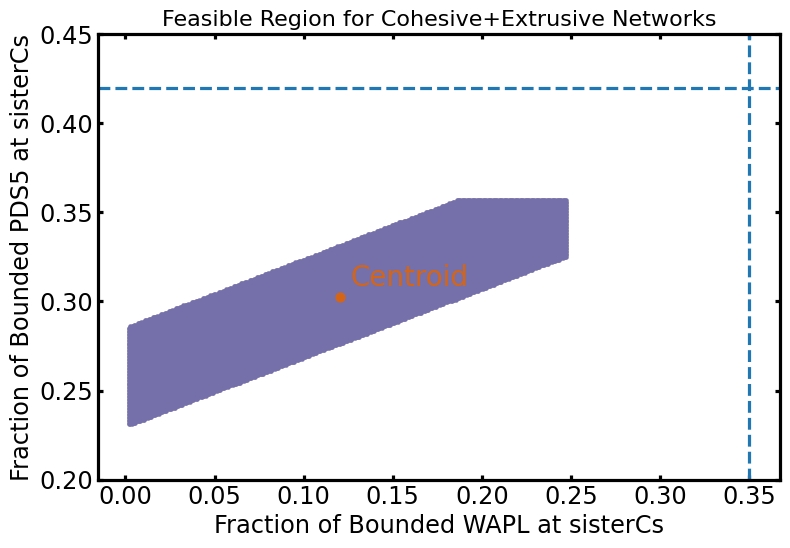

In [64]:
## Plot the feasible region
plt.rcParams['svg.fonttype']='none' 
positive_xy_scan
fig, ax = plt.subplots(figsize=(8, 6))
# Extract x and y values
x_vals = [point[0] for point in positive_xy_scan]
y_vals = [point[1] for point in positive_xy_scan]
# Create a scatter plot of x vs y
ax.scatter(x_vals, y_vals, s=5, color='#7670AA')
ax.scatter(centroids[0], centroids[1], s=40, label="Centroid", color = '#D56516')
plt.annotate(
    "Centroid",
    (centroids[0], centroids[1]),
    textcoords="offset points",
    xytext=(8, 8),
    fontsize=20,
    color = '#D56516'
)
plt.axhline(y=0.42, linestyle='--')  # choose your y value
plt.axvline(x=0.35, linestyle='--')   # choose your x value

ax.set_ylim(0.2, 0.45)
ax.set_xlabel("Fraction of Bounded WAPL at sisterCs", fontsize = 14)
ax.set_ylabel("Fraction of Bounded PDS5 at sisterCs",  fontsize = 14)
ax.set_aspect('equal')
ax.tick_params(axis='both', labelsize=14)  # You can increase this value as needed
plt.title("Feasible Region for Cohesive+Extrusive Networks", fontsize=16)
useLargeSize(plt, ax, marker_lines = None, fontsize = 'xx-large',fontproperties=None, LW=2.3)
plt.savefig("Fig3_SI_Feasible_region.svg", format='svg')
plt.show()

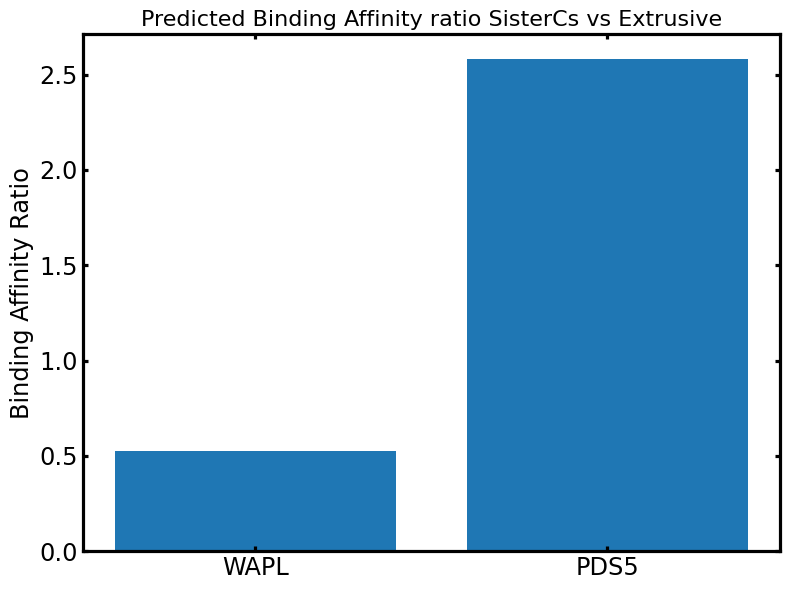

In [69]:
# Compute values
plt.rcParams['svg.fonttype']='none' 
fig, ax = plt.subplots(figsize=(8, 6))

val1 = centroids[0] / (0.35 - centroids[0])
val2 = (centroids[1]) / (0.42 - centroids[1])

# Bar plot
labels = ["WAPL", "PDS5"]
values = [val1, val2]

ax.bar(labels, values)

ax.set_ylabel("Binding Affinity Ratio", fontsize=14)
ax.set_title("Predicted Binding Affinity ratio SisterCs vs Extrusive", fontsize=16)
ax.tick_params(axis='both', labelsize=14)
useLargeSize(plt, ax, marker_lines = None, fontsize = 'xx-large',fontproperties=None, LW=2.3)
plt.savefig("Fig3_SI_Ratio.svg", format='svg')
plt.show()